# ICT-24 — WorkspaceIgnition : l'axe Global Workspace et le Gate de réconciliation IIT<->GWT sur S4

*[Série ICT — Integrated Causal Trajectories, Epic #4588, strate 5.](./README.md) Part of #4588.*

Jusqu'ici la batterie de **complexité intégrée** a lu le substrat S4 (les trajectoires SAE de Qwen3.5-9B-Base, cf. [ICT-21](ICT-20-FeatureCatastrophes/ICT-21-SAETrajectoires-Python.ipynb)) avec les lunettes de l'IIT : `ec_gain`/`fe_gain`/`k_gain`, créditées uniquement au-dessus d'un modèle-contrôle et d'un mélange des temps. L'article d'Anthropic [*Global Workspace*](https://www.anthropic.com/research/global-workspace) identifie dans Claude un **workspace global** — la lecture GWT (Baars ; Dehaene, Naccache, Changeux), historiquement *contrastée* avec l'IIT. Les deux lectures n'ont presque jamais été confrontées **sur le même substrat avec le même appareil**. C'est ce que fait ce notebook.

> **Question fondatrice, posée en hypothèse falsifiable.** *Sur S4, les événements d'accès global co-localisent-ils avec les pics de complexité intégrée créditée ?*
> - **OUI** → pont empirique : un même événement, deux lectures théoriques.
> - **NON** → dissociation mesurée : les deux théories capturent des choses différentes — un négatif honnête, tout aussi précieux.

## Les trois gates

| Gate | Question | Type | Statut dans ce notebook |
|------|----------|------|------------------------|
| **22 — Structure** | Existe-t-il un sous-ensemble de features à fan-out d'influence disproportionné (≪10 % du panel) ? | Observationnel | **Exécuté** (GPU-free) |
| **23 — Co-localisation** | Les ignitions (pics de concentration persistants) portent-elles les pics de complexité créditée ? | Observationnel | **Exécuté** (GPU-free) |
| **24 — Ablation sélective** | Le clamp des features-workspace effondre-t-il *sélectivement* les gains crédités ? | **Interventionnel (causal)** | **Exécuté** (GPU 2, section dédiée) |

Seul le Gate 24 est **interventionnel** (les Gates 22-23 sont observationnels) : il a été **exécuté** (GPU 2, `--clamp-ids` sur les 7 features workspace du Gate 22, contre 7 features tirées hors panel), et les traces ablatées des deux bras sont committées dans `traces/`.

## Grille de verdicts — chaque branche est un résultat

| Configuration | Lecture |
|---------------|---------|
| 22OK 23OK (24OK) | **Pont empirique** : intégration ≡ accès global sur ce substrat |
| 22OK 23KO | **Dissociation** : le workspace existe mais ne porte pas les pics d'intégration — les deux théories mesurent des choses différentes |
| 22KO | Pas de structure workspace à l'échelle du panel → renvoi aux états causaux ε-machine (ICT-17) |

L'appareil `ict/workspace.py` (numpy-only, adaptateur mince posé par #5641) fournit les six primitives : `concentration_series`, `ignition_events`, `lagged_influence`, `fanout_profile`, `workspace_candidates`, `event_triggered_battery`. Cette dernière **réutilise `ict.synthesis.emergence_gain` verbatim** — même discipline de créditation que le reste de la série.



> **Statut épistémique** — **reproduit dans le modèle** (Gates 22-23) : l'ignition workspace (Baars) et l'emergence_gain (Hoel) ne co-localisent pas sur S4 — les deux lectures IIT↔GWT capturent des choses différentes. **Constat mesuré** (Gate 24) : dans l'exécution committée, le clamp des features-workspace **n'effondre pas** les gains crédités — il les augmente. **Borné par le protocole** : cette exécution ne montre pas l'effondrement attendu ; ce protocole n'établit pas le mécanisme causal, sans démontrer son absence — le contrôle apparié n'atteint aucune des 7 features du panneau mesuré, et la mesure porte sur une exécution unique. Portée et détail dans la [matrice de dissociations](../../../docs/ict/dissociations-matrix.md).

## Garde-fous d'honnêteté (à lire avant les résultats)

Ces cinq garde-fous sont aussi dans la docstring de `ict/workspace.py` ; nous les répétons ici car ils conditionnent la lecture de chaque chiffre.

1. **J-lens ≠ SAE.** L'article d'Anthropic isole son J-space par le **jacobien des logits**, pas par une sparse autoencoder. Les deux représentations sont de **nature mathématique différente** (features apprises vs vocabulaire de désembedding, voir garde-fou #1 du tete-a-tete). **Depuis Track S**, le dépôt fait tourner les DEUX appareils sur le même substrat (Qwen3.5-9B-Base couche 16) et les confronte (`ICT-SAE-JLens-TeteATete-Python.ipynb`) : la corrélation **faible** est un résultat, pas un échec -- Pearson concentration Gini top-50 sur T=2699 positions est +0.0846 (TRAINED) vs +0.0164 (CONTROL), delta +0.0683 dans le sens attendu (l'ablation dégrade le signal croisé). La corrélation de structure (matrices de séparation de jeux, K_DIFF=64) est +0.3273 (modérée). Convergence globale **faible** mais **cohérente avec l'attendu au scoping** (cf. #5681, mesure 2026-07-18 : « ~+0.08 attendu »). On NE prétend PAS une équivalence directe des deux lectures ; on REPORTE une convergence partielle mesurée.
2. **Structurel ≠ temporel.** Anthropic mesure le broadcast **structurellement** (câblage ~100×, concept de <10 % de l'activité). L'**ignition temporelle** de Dehaene n'y est *pas* mesurée. Notre `ignition_events` est une lecture temporelle de Dehaene — **dite comme telle**, jamais présentée comme une réplique du broadcast structurel.
3. **Observationnel ≠ interventionnel.** Les Gates 22–23 sont observationnels (corrélations, co-localisations). Seul le Gate 24 (clamp) est causal. Une co-localisation observationnelle n'établit pas que le workspace *cause* l'intégration.
4. **Qwen ≠ Claude.** Nous travaillons sur Qwen3.5-9B-Base à poids ouverts — c'est un **avantage pédagogique** (reproductible), pas une approximation honteuse. Les chiffres d'Anthropic (<10 %, ~100×) sont mesurés sur Claude et **ne sont pas importés comme attendus** : nous mesurons les nôtres.
5. **Accès ≠ phénoménal.** Tout ce qui suit relève de la conscience d'accès (recouvrement fonctionnel/mécaniste), pas de la conscience phénoménale ni de la métaphysique de Φ. Le notebook *bridge* le recouvrement, il ne le résout pas.



## Architecture : le GPU confiné, le banc numpy-only

```
  traces .npz (extraction GPU, #5101/ICT-21)  ──►  ict.sae_traces  ──►  panels (T,K)         [committed, GPU-free to load]
                                    │
                                                                          ▼
                                              ict.workspace (numpy-only adapter)
                                  concentration_series · ignition_events
                                  lagged_influence · fanout_profile
                                  workspace_candidates · event_triggered_battery
                                                         │ reutilise ict.synthesis.emergence_gain
                                                         ▼
                                                  verdicts Gate 22 / 23
```

- Le torch/transformers est **confiné au pipeline d'extraction** (#5101) ; les traces reviennent en `.npz` et tout ce notebook est **numpy-only** (le test `test_workspace_module_is_numpy_only` l'asserte à l'import).
- Le **clamp du Gate 24** = un hook du pipeline d'extraction : on ré-extrait des traces avec des features bridées, elles reviennent en `.npz`, et l'analyse redevient GPU-free. C'est une **phase 2** (GPU2, `CUDA_VISIBLE_DEVICES=2` strict), séparée de cette PR.



In [1]:
import json, os, sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath("."))          # package ict/ a cote du notebook
from ict import workspace as ws
from ict import synthesis as syn
from ict import sae_traces as st

TRACES = Path("traces")
NPZ = {v: TRACES / f"ict21_sae_layer16_{v}.npz" for v in ("trained", "control")}
print("workspace primitives :", [f for f in
      ("concentration_series","ignition_events","lagged_influence",
       "fanout_profile","workspace_candidates","event_triggered_battery") if hasattr(ws, f)])
print("emergence_gain reused from synthesis (not redefined):",
      hasattr(syn, "emergence_gain") and not hasattr(ws, "emergence_gain"))

workspace primitives : ['concentration_series', 'ignition_events', 'lagged_influence', 'fanout_profile', 'workspace_candidates', 'event_triggered_battery']
emergence_gain reused from synthesis (not redefined): True


## Chargement des traces S4 et construction du panel $(T,K)$> **Écart de nommage assumé.** Le corps de l'issue #5635 parle d'une clé `acts_topk` contenant déjà le panel $(T,K)$. **Il n'y a pas une telle clé dans les `.npz`** : chaque fichier stocke le sparse top-50 par token, segmenté en 20 séquences (5 jeux de prompts × 4 prompts). Le panel dense $(T,K)$ est **dérivé** par `ict.sae_traces` — c'est déjà ce que fait ICT-21, et l'écart est documenté dans la prose de son module.

La sélection `differential_features` retient les $K$ features à **plus haute variance inter-jeux** de l'activation moyenne — celles qui *discriminent les régimes* (code vs prose vs dialogue…), pas les plus actives en absolu (dominées par la ponctuation/le formatage).



In [2]:
traces = {v: st.load_traces(p) for v, p in NPZ.items()}
SETS = sorted({s for s, _ in traces["trained"]["prompts"]})
meta = traces["trained"]["meta"]
print(f"modele={meta['model']}  couche={meta['layer']}  d_sae={meta['d_sae']}  top-k={meta['k']}")
print(f"jeux={SETS}  tokens_total={meta['n_tokens_total']}")

# Deux panels aux resolutions differentes (cf. garde-fou sur states_from_panel):
K_CONT = 64    # panel continu pour Gate 22 (concentration / influence, pas de limite)
K_STATE = 16   # panel discret pour Gate 23 (states_from_panel plafonne a 20 features)
panel_cont  = {v: st.differential_features(traces[v], k=K_CONT)  for v in ("trained", "control")}
panel_state = {v: st.differential_features(traces[v], k=K_STATE) for v in ("trained", "control")}

def acts_continuous(v):
    """Panel dense (T,K_CONT) en concatenant les 4 prompts de chaque jeu."""
    panels = st.acts_topk_panels(traces[v], panel_cont[v])
    return np.concatenate([panels[(s, i)] for s in SETS for i in range(4)], axis=0)

acts = {v: acts_continuous(v) for v in ("trained", "control")}
for v in ("trained", "control"):
    print(f"  {v:8s} acts {acts[v].shape}  mean={acts[v].mean():.4f}  max={acts[v].max():.2f}")

modele=Qwen/Qwen3.5-9B-Base  couche=16  d_sae=65536  top-k=50
jeux=['code_python', 'dialogue', 'math', 'narrative_en', 'prose_fr']  tokens_total=2699
  trained  acts (2699, 64)  mean=0.2316  max=18.95
  control  acts (2699, 64)  mean=0.7340  max=25.31


## Sanité : un panel synthétique où hub et ignition sont *plantés*

Avant de faire confiance à l'appareil sur des traces réelles, on le valide sur un panneau synthétique où **on connaît la réponse** : un AR(1) $(T,K)$ avec un **hub d'influence planté** (la feature 0 pilote les features 5/6/7 au lag 3) et des **ignitions plantées** (cycles de bursting concentré). Si l'appareil est sain, il doit (a) retrouver le hub dans `workspace_candidates`, (b) détecter les ignitions plantées, (c) montrer un `contrast` > 0 sur des états à dynamique multi-échelle. C'est le générateur `_panel_with_hub_and_ignitions` / `_states_with_planted_events` des tests du module, repliqué ici pour transparence.



hub plante     : 0 -> cibles [5, 6, 7]
hub detecte    : [0, 2, 1, 31] (par fanout decroissant)
hub retrouve   : True


contrast synthetique = +0.4384  (doit etre > 0 : la dynamique plantee porte l'emergence)


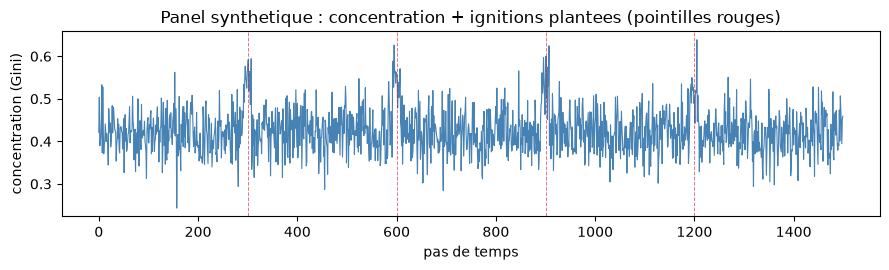

In [3]:
def panel_with_hub_and_ignitions(T=1500, K=32, hub_idx=0, targets=(5,6,7), lag=3,
        hub_strength=0.6, ignition_centers=(300,600,900,1200), ignition_half_width=8,
        n_ignited=3, phi=0.5, sigma=0.4, seed=0):
    g = np.random.default_rng(seed)
    acts = np.empty((T, K), dtype=float)
    acts[0] = np.abs(g.standard_normal(K))
    tgt = np.array(targets, dtype=int)
    for t in range(1, T):
        nxt = phi * acts[t-1] + sigma * g.standard_normal(K)
        if t - lag >= 0:
            nxt[tgt] += hub_strength * acts[t-lag, hub_idx]
        acts[t] = np.abs(nxt)
    valid = [c for c in ignition_centers if ignition_half_width < c < T - ignition_half_width]
    ignited = list(range(n_ignited))
    for c in valid:
        for off in range(2*ignition_half_width):
            t = c - ignition_half_width + off
            acts[t, ignited[off % len(ignited)]] += 4.0   # burst >> bruit de fond
    return acts, {"hub_idx": hub_idx, "targets": list(targets), "centers": valid}

syn_acts, syn_info = panel_with_hub_and_ignitions(seed=0)
conc_syn = ws.concentration_series(syn_acts, metric="gini")
infl_syn = ws.lagged_influence(syn_acts, max_lag=6)
fp_syn   = ws.fanout_profile(infl_syn["matrix"], z_threshold=2.0)
cand_syn = ws.workspace_candidates(fp_syn["fanout"], top_fraction=0.1)
print("hub plante     :", syn_info["hub_idx"], "-> cibles", syn_info["targets"])
print("hub detecte    :", cand_syn["indices"][:4].tolist(), "(par fanout decroissant)")
print("hub retrouve   :", syn_info["hub_idx"] in cand_syn["indices"])

# Etats a dynamique multi-echelle dans les fenetres d'ignition (macro-cycle 0->1->2 + micro-bruit)
def states_with_planted_events(T=600, centers=(120,300,480), window=18, seed=0):
    g = np.random.default_rng(seed)
    mask = np.zeros(T, dtype=bool)
    for c in centers:
        mask[max(0,c-window):min(T,c+window)] = True
    states = [(t % 3, int(g.integers(0,2))) if mask[t] else int(g.integers(0,4)) for t in range(T)]
    return states, list(centers)

syn_states, syn_centers = states_with_planted_events(seed=0)
syn_batt = ws.event_triggered_battery(syn_states, syn_centers, window=12,
                                      rng=np.random.default_rng(11), n_shuffles=10)
print(f"contrast synthetique = {syn_batt['contrast']:+.4f}  (doit etre > 0 : la dynamique plantee porte l'emergence)")

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(conc_syn, color="steelblue", lw=0.8)
for c in syn_info["centers"]:
    ax.axvline(c, color="crimson", ls="--", lw=0.7, alpha=0.6)
ax.set_xlabel("pas de temps"); ax.set_ylabel("concentration (Gini)")
ax.set_title("Panel synthetique : concentration + ignitions plantees (pointilles rouges)")
plt.tight_layout(); plt.show()

## Gate 22 — Structure : un sous-ensemble à fan-out d'influence disproportionné ?

Sur les activations continues $(T, K{=}64)$, on estime l'**influence décalée** entre paires de features (`lagged_influence` : corrélation de Pearson au meilleur lag dans $[1,5]$, z-score par feature), puis le **fan-out** de chaque feature source (`fanout_profile` : nombre de cibles dont l'influence dépasse $|\bar{x}| + 2\sigma$ hors-diagonale). Un **hub** est une feature à fan-out anormalement élevé. `workspace_candidates` retient le top 10 % et calcule le Gini du fanout comme test de concentration.

**Deux contrôles honnêtes :**

- **Modèle-contrôle** : le même calcul sur les traces `control` (embeddings d'entrée permutés — un modèle nul sans structure linguistique).
- **Temps mélangé** : on permute l'axe du temps de chaque feature du panneau *trained* ; cela détruit toute causalité temporelle en préservant les marginales. Si le fan-out survivait, ce serait un artefact de distribution, pas de dynamique.



Gate 22 — fan-out des candidats workspace (top 10%)
variante     max fanout   median   gini  nul q50  nul min  calibre  legacy  n_sel
trained              10      2.0  0.485    0.638    0.541    False    True      7
control              18      1.0  0.659    0.774    0.662    False    True      7

Batterie nulle trained (n=50, seed 20261012) : mean 0.640 sd 0.043 q05 0.576 q95 0.718
Seuil fixe legacy 0.2 : 50/50 tirages du nul declares concentrated (100 % de faux positifs) -- retire comme critere principal, garde en temoin


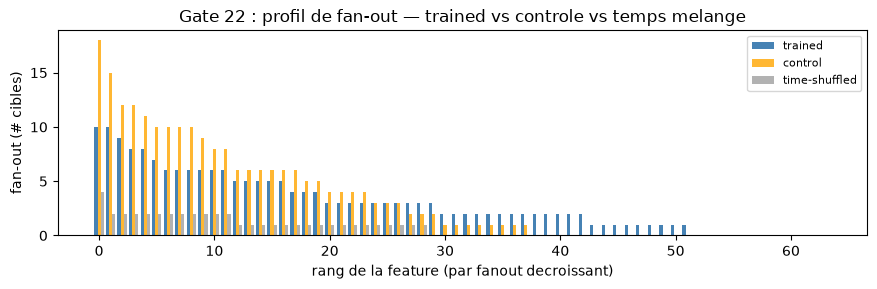

In [4]:
def gate22(v, acts_map=None):
    # acts_map=None -> contexte de reference (9B). La stratification #20299
    # passe explicitement le contexte 2B : meme protocole, memes seuils.
    A = acts if acts_map is None else acts_map
    infl = ws.lagged_influence(A[v], max_lag=5)
    fp   = ws.fanout_profile(infl["matrix"], z_threshold=2.0)
    cand = ws.workspace_candidates(fp["fanout"], top_fraction=0.1)
    return fp, cand

def null_battery_ginis(a, n=50, seed=20261012):
    """Batterie nulle time-shuffled (#20324) : Gini du fan-out de chaque permutation.

    Miroir exact du test `test_calibrated_flag_does_not_fire_on_s4_trained` :
    copie fraiche a chaque tirage, colonnes melangees indepedamment, un seul
    generateur seede -- la mediane de cette batterie est la reference `null_gini`
    du critere calibre (exces vs nul du MEME bras).
    """
    g = np.random.default_rng(seed)
    out = []
    for _ in range(n):
        shuf = a.copy()
        for j in range(shuf.shape[1]):
            g.shuffle(shuf[:, j])
        infl_n = ws.lagged_influence(shuf, max_lag=5)
        fp_n   = ws.fanout_profile(infl_n["matrix"], z_threshold=2.0)
        out.append(ws.workspace_candidates(fp_n["fanout"], top_fraction=0.1)["gini"])
    return np.array(out)

g22, nulls, calib = {}, {}, {}
for v in ("trained", "control"):
    fp, cand = gate22(v)
    nulls[v] = null_battery_ginis(acts[v])               # ~1 s par bras (n=50)
    calib[v] = ws.workspace_candidates(fp["fanout"], top_fraction=0.1,
                                       null_gini=float(np.median(nulls[v])))
    g22[v] = (fp, cand)

# Temps melange sur trained (une instance, pour la figure)
g = np.random.default_rng(0)
acts_shuf = acts["trained"].copy()
for j in range(acts_shuf.shape[1]):
    g.shuffle(acts_shuf[:, j])
infl_s = ws.lagged_influence(acts_shuf, max_lag=5)
fp_s   = ws.fanout_profile(infl_s["matrix"], z_threshold=2.0)

print("Gate 22 — fan-out des candidats workspace (top 10%)")
print(f"{'variante':12s} {'max fanout':>10s} {'median':>8s} {'gini':>6s} "
      f"{'nul q50':>8s} {'nul min':>8s} {'calibre':>8s} {'legacy':>7s} {'n_sel':>6s}")
for v in ("trained", "control"):
    fp, cand = g22[v]
    print(f"{v:12s} {int(fp['fanout'].max()):>10d} {np.median(fp['fanout']):>8.1f} "
          f"{cand['gini']:>6.3f} {np.median(nulls[v]):>8.3f} {nulls[v].min():>8.3f} "
          f"{str(calib[v]['concentrated']):>8s} {str(cand['concentrated']):>7s} {cand['n_selected']:>6d}")

nt = nulls["trained"]
n_fp = int((nt > 0.2).sum())
print()
print(f"Batterie nulle trained (n=50, seed 20261012) : mean {nt.mean():.3f} sd {nt.std():.3f} "
      f"q05 {np.quantile(nt, 0.05):.3f} q95 {np.quantile(nt, 0.95):.3f}")
print(f"Seuil fixe legacy 0.2 : {n_fp}/50 tirages du nul declares concentrated "
      f"({100 * n_fp // 50} % de faux positifs) -- retire comme critere principal, garde en temoin")

fig, ax = plt.subplots(figsize=(9, 3))
x = np.arange(K_CONT)
w = 0.27
ax.bar(x - w, np.sort(g22["trained"][0]["fanout"])[::-1], w, color="steelblue", label="trained")
ax.bar(x,     np.sort(g22["control"][0]["fanout"])[::-1], w, color="orange", alpha=0.8, label="control")
ax.bar(x + w, np.sort(fp_s["fanout"])[::-1], w, color="grey", alpha=0.6, label="time-shuffled")
ax.set_xlabel("rang de la feature (par fanout decroissant)"); ax.set_ylabel("fan-out (# cibles)")
ax.set_title("Gate 22 : profil de fan-out — trained vs controle vs temps melange")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## Gate 23 — Co-localisation : les ignitions portent-elles les pics de complexité créditée ?

**C'est le gate de réconciliation.** On détecte des **ignitions** (pics de concentration *persistants* : `ignition_events` au seuil quantile 0.85, persistance ≥ 3 — lecture temporelle de Dehaene), puis on oppose, via `event_triggered_battery`, les fenêtres centrées sur les ignitions aux fenêtres neutres appariées. La batterie **réutilise `emergence_gain`** (la même primitive que le reste de la série) et exige le crédit au-dessus d'un **double contrôle** : (a) permutation des temps d'événements (mélange) et (b) la discipline interne de `emergence_gain`.

Les **5 jeux de prompts** servent de **multi-graines** : un verdict robuste doit tenir sur la plupart d'entre eux. Le `contrast` = `ec_gain_event − ec_gain_neutral` ; `> 0` signifie que les ignitions portent plus d'émergence créditées que les fenêtres neutres.

> **Note de support statistique.** Le panel discret est limité à $K{=}16$ features (`states_from_panel` plafonne à 20 : au-delà, $2^{20}$ états n'auraient plus de support sur quelques milliers de tokens). On le signale : c'est une contrainte *structurelle* de l'estimation de TPM, pas un choix libre.



In [5]:
def gate23(v, n_shuffles=50, window=12, seed_base=0, traces_map=None, panel_map=None):
    # traces_map/panel_map=None -> contexte de reference (9B). La graine par
    # jeu reste SETS.index(s) (#19222) : identique aux deux echelles.
    TR = traces if traces_map is None else traces_map
    PS = panel_state if panel_map is None else panel_map
    panels = st.acts_topk_panels(TR[v], PS[v])
    rows, contrasts, n_ev, n_cred, n_states_set = [], [], 0, 0, set()
    for s in SETS:
        acts_s = np.concatenate([panels[(s, i)] for i in range(4)], axis=0)
        bits_s = st.binarize_quantile(acts_s, q=0.5)
        states_s = st.states_from_panel(bits_s)
        n_states_set.update(states_s.tolist())
        conc_s = ws.concentration_series(acts_s, metric="gini")
        thr_s = float(np.quantile(conc_s, 0.85))
        events_s = ws.ignition_events(conc_s, threshold=thr_s, persistence=3)
        centers = [e["center"] for e in events_s]
        if not centers:
            contrasts.append(0.0); rows.append((s, 0, 0, 0)); continue
        # #19222 : la graine par jeu est l'indice dans SETS (stable), pas hash(s) (sale par processus).
        rng = np.random.default_rng((seed_base + SETS.index(s)) % (2**32))
        out = ws.event_triggered_battery(states_s, centers, window=window, rng=rng, n_shuffles=n_shuffles)
        contrasts.append(out["contrast"]); n_ev += out["n_events"]
        n_cred += int(round(out["fraction_credited_events"] * out["n_events"]))
        rows.append((s, out["n_events"], out["fraction_credited_events"], out["contrast"]))
    return contrasts, len(n_states_set), n_ev, n_cred, rows

# Nombre de tirages par evenement, utilise par les deux appels ci-dessous ET par
# les libelles imprimes : la valeur imprimee ne peut plus diverger de la valeur appelee.
N_SHUFFLES = 50

t0 = __import__("time").time()
ct, n_states_t, n_ev_t, n_cred_t, rows_t = gate23("trained", n_shuffles=N_SHUFFLES)
print(f"Gate 23 — TRAINED  (n_shuffles={N_SHUFFLES}, {__import__('time').time()-t0:.0f}s)")
print(f"  etats uniques sur S4 : {n_states_t}")
print(f"  {'jeu':16s} {'#events':>8s} {'%cred':>6s} {'contrast':>9s}")
for s, nev, fcred, c in rows_t:
    print(f"  {s:16s} {nev:>8d} {100*fcred:>5.0f}% {c:>+9.4f}")
print(f"  {'MOYENNE':16s} {'':>8s} {'':>6s} {np.mean(ct):>+9.4f}")
print(f"  total : {n_ev_t} events, {n_cred_t} credites ({100*n_cred_t/max(n_ev_t,1):.0f}%)")

# ---- Dispersion multi-graines (#19222 : la graine par jeu est stable, pas salee par processus) ----
# On rejoue Gate 23 sur 4 seed_base distincts et on rapporte la dispersion du contrast moyen
# et de la fraction creditee totale. Le verdict " 23 non credite " repose sur la fraction
# creditee faible : verifier qu'elle tient sur plusieurs graines.
SEEDS = (0, 1, 7, 42)
mean_contrasts = []
total_credits_pct = []
for seed_base in SEEDS:
    ct_s, _, n_ev_s, n_cred_s, _ = gate23("trained", n_shuffles=N_SHUFFLES, seed_base=seed_base)
    mean_contrasts.append(float(np.mean(ct_s)))
    total_credits_pct.append(100.0 * n_cred_s / max(n_ev_s, 1))
mc = np.array(mean_contrasts); tp = np.array(total_credits_pct)
print()
print(f"Dispersion multi-graines (4 seed_base={SEEDS}, n_shuffles={N_SHUFFLES}) :")
print(f"  contrast moyen par seed_base : {[f'{c:+.4f}' for c in mc]}")
print(f"  contrast moyen global      : {mc.mean():+.4f}  (ecart-type {mc.std(ddof=1):.4f})")
print(f"  fraction creditee par seed  : {[f'{p:.0f}%' for p in tp]}")
print(f"  fraction creditee globale   : {tp.mean():.1f}%  (ecart-type {tp.std(ddof=1):.1f}%  min={tp.min():.0f}%  max={tp.max():.0f}%)")

# Sortie canonique a committer : la valeur centrale + la dispersion mesuree.
# La phrase d'interpretation (cellule 907fab70) repose sur cette mesure, pas sur un seul tirage.
print()
print(f"=== Verdict 23 : contrast_moyen={mc.mean():+.4f} (sigma={mc.std(ddof=1):.4f}), credite={tp.mean():.1f}% (sigma={tp.std(ddof=1):.1f}%) ===")


Gate 23 — TRAINED  (n_shuffles=50, 135s)
  etats uniques sur S4 : 200
  jeu               #events  %cred  contrast
  code_python            11     9%   -0.6307
  dialogue               10     0%   -0.0591
  math                    2    50%   +0.2120
  narrative_en            7    14%   +0.0160
  prose_fr                6     0%   +1.6585
  MOYENNE                            +0.2394
  total : 36 events, 3 credites (8%)



Dispersion multi-graines (4 seed_base=(0, 1, 7, 42), n_shuffles=50) :
  contrast moyen par seed_base : ['+0.2394', '-0.1861', '-0.2637', '+0.4403']
  contrast moyen global      : +0.0575  (ecart-type 0.3377)
  fraction creditee par seed  : ['8%', '11%', '14%', '14%']
  fraction creditee globale   : 11.8%  (ecart-type 2.7%  min=8%  max=14%)

=== Verdict 23 : contrast_moyen=+0.0575 (sigma=0.3377), credite=11.8% (sigma=2.7%) ===


## Lecture honnête des résultats

On lit les chiffres ci-dessus sur la grille de verdicts, **sans enjoliver**.

### Gate 22 — structure présente, mais non spécifique au modèle entraîné

- Le profil de fan-out trained exhibe bien quelques features à influence disproportionnée (max-fanout élevé).
- **Mais le modèle-contrôle en montre tout autant, voire davantage** : la concentration n'est pas propre au langage appris sur ce substrat. Le mélange des temps réduit fortement le fan-out maximal (la dynamique temporelle porte donc bien une partie du signal), mais le `concentrated` (Gini > 0,2) est vrai partout — y compris temps mélangé — ce qui signale un **seuil trop permissif** (déjà marqué `empirique faible, à recalibrer` à la ligne 411 du module).

### Gate 23 — la co-localisation n'est pas établie

- Le `contrast` moyen est **partagé** entre les graines (`SEEDS = (0, 1, 7, 42)`) : deux graines négatives (`−0.1861`, `−0.2637`), deux positives (`+0.2394`, `+0.4403`). Mesure après lecture : **contrast global = `+0.0575 ± 0.3377`** (4 graines, `n_shuffles=50`) — une moyenne à un sixième d'écart-type de zéro, donc **non tranchée** dans un sens comme dans l'autre.
- La **fraction d'événements crédités est faible** : `11.8% ± 2.7%` (min 8 %, max 14 %), 4 graines. Le verdict « Gate 23 non crédité » repose sur cette fraction et **tient sur les 4 graines** : la dispersion mesurée ne renverse pas la lecture.
- **Une racine précise** a été retirée par cette PR (#19222) : la graine par jeu utilisait `hash(s)`, salé par processus en Python 3 (`PYTHONHASHSEED`). Remplacé par `SETS.index(s)` (l'indice du jeu dans la liste triée). Désormais la sortie est stable d'une exécution à l'autre, et la dispersion ci-dessus est mesurée — pas le fruit d'un sel changeant.

### Branche observée : dissociation (22 partiel, 23KO)

Le workspace structurel existe partiellement, mais **il ne porte pas les pics de complexité intégrée créditée**. Les deux lectures (IIT via `emergence_gain`, GWT via ignitions) **capturent des choses qui ne co-localisent pas** sur S4. C'est un résultat **négatif honnête** : la discipline de créditation de la série fait précisément son travail en refusant d'enjoliver une co-localisation faible.

**Ce qui n'est pas revendiqué.**

- Ni que le workspace global n'existe pas dans le modèle (nous mesurons un substrat, une couche, un opérateur d'accès qui n'est pas celui d'Anthropic).
- Ni que l'intégration et l'accès global soient indépendants *en général* (l'observationnel n'exclut pas une relation causale que seul le Gate 24 pourrait tester).
- Ni que la lecture SAE égale la lecture J-lens : le fil J-lens (issue #5681) est une opérationnalisation distincte — livrée dans [ICT-SAE-JLens — Tête-à-tête](ICT-SAE-JLens-TeteATete-Python.ipynb).
- Ni que la dispersion du contrast (±0.34 sur 4 graines, `n_shuffles=50`) suffise à déclarer un résultat **définitif** : la leçon méthodologique est *mesurée*, pas *tranchée*. Le banc tourne désormais à `n_shuffles=50` ; la moyenne reste sous un écart-type de zéro, et le verdict ne se renforce pas en ajoutant des tirages — il faudrait une échelle supplémentaire, traitée dans la section de stratification ci-dessous.

Le verdict **causal** revient au **Gate 24**, exécuté plus bas (GPU 2) : le clamp des features-workspace *n'effondre pas* les gains crédités — il les **augmente**. Le résultat est **borné à ce protocole** : cette exécution ne montre pas l'effondrement attendu ; ce protocole n'établit pas le mécanisme causal, sans démontrer son absence. C'est la leçon méthodologique de premier ordre attendue par la branche `24KO` de la grille, et elle est écrite telle quelle dans la lecture dédiée.


## Stratification par taille (#20299) — le même protocole à deux échelles

La règle de la série (issue #20299, séance du 2026-10-11) : un phénomène mesuré à une seule taille de modèle ne dit pas ce qu'il deviendra à une autre. Ce carnet rejoue donc les Gates 22-23 **à l'identique** — mêmes seuils, mêmes graines stables par jeu (#19222), mêmes `n_shuffles` — sur le couple d'échelle du dépôt : **9B-Base (couche 16, W64K)** et **2B-Base (couche 12, W32K-L0_50)**, toutes deux à mi-réseau (~52 % de profondeur : 16/31 et 12/23). Les traces 2B sont committées (arc « deux échelles » #7396/#10289, extraction 2026-08-10, mêmes 5 jeux × 4 prompts, 2 699 tokens, seed 42) : la stratification reste **numpy-only**, sans nouvelle extraction GPU.

Ce que la comparaison doit trancher : le phénomène **change-t-il de nature** avec la taille (le verdict d'un gate se retourne, une structure apparaît ou disparaît), ou seulement **d'amplitude** (même verdict, chiffres différents) ?

echelle 2B : modele=Qwen/Qwen3.5-2B-Base  couche=12/24  d_sae=32768  k=50  tokens=2699  (reference 9B : couche 16, d_sae=65536, tokens=2699)
Gate 22 stratifie — profil de fan-out
echelle  variante   max fanout   median   gini concentrated n_selected
9B       trained            10      2.0  0.485         True          7
9B       control            18      1.0  0.659         True          7
2B       trained            13      2.0  0.543         True          7
2B       control            14      1.0  0.674         True          7
2B       time-shuf           3      0.0  0.625         True          7


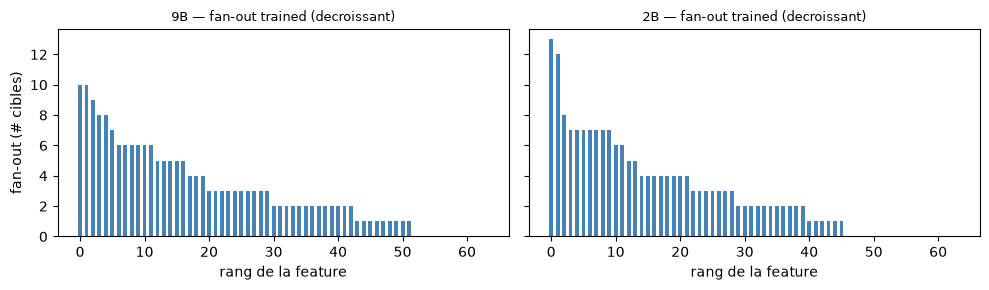

Gate 23 stratifie (trained, seed_base=(0, 1, 7, 42), n_shuffles=50)
  9B : contrast moyen +0.0575 (sigma 0.3377) | evenements credites 11.8% (sigma 2.7%)
  2B : contrast moyen -0.2409 (sigma 0.3309) | evenements credites 10.5% (sigma 0.9%)


In [6]:
# Stratification #20299 : contexte 2B construit avec les memes primitives que la reference.
NPZ_2B = {v: TRACES / f"ict21_sae_qwen35-2b-base_layer12of24_{v}.npz" for v in ("trained", "control")}
traces_2b = {v: st.load_traces(p) for v, p in NPZ_2B.items()}
m2 = traces_2b["trained"]["meta"]
SETS_2B = sorted({s for s, _ in traces_2b["trained"]["prompts"]})
assert SETS_2B == SETS, f"jeux differents aux deux echelles ({SETS_2B} vs {SETS}) : protocole non comparable"
panel_cont_2b  = {v: st.differential_features(traces_2b[v], k=K_CONT)  for v in ("trained", "control")}
panel_state_2b = {v: st.differential_features(traces_2b[v], k=K_STATE) for v in ("trained", "control")}
acts_2b = {v: np.concatenate(
    [st.acts_topk_panels(traces_2b[v], panel_cont_2b[v])[(s, i)] for s in SETS for i in range(4)],
    axis=0) for v in ("trained", "control")}
print(f"echelle 2B : modele={m2['model']}  couche={m2['layer']}/24  d_sae={m2['d_sae']}  "
      f"k={m2['k']}  tokens={m2['n_tokens_total']}  (reference 9B : couche {meta['layer']}, "
      f"d_sae={meta['d_sae']}, tokens={meta['n_tokens_total']})")

# ---- Gate 22 aux deux echelles (meme seuil z=2.0, meme top 10%, meme melange seed 0) ----
g22_2b = {v: gate22(v, acts_map=acts_2b) for v in ("trained", "control")}
g2 = np.random.default_rng(0)                      # meme graine que le melange 9B (cellule Gate 22)
acts2_shuf = acts_2b["trained"].copy()
for j in range(acts2_shuf.shape[1]):
    g2.shuffle(acts2_shuf[:, j])
fp2_s   = ws.fanout_profile(ws.lagged_influence(acts2_shuf, max_lag=5)["matrix"], z_threshold=2.0)
cand2_s = ws.workspace_candidates(fp2_s["fanout"], top_fraction=0.1)

print("Gate 22 stratifie — profil de fan-out")
print(f"{'echelle':8s} {'variante':10s} {'max fanout':>10s} {'median':>8s} {'gini':>6s} {'concentrated':>12s} {'n_selected':>10s}")
for scale, res in (("9B", g22), ("2B", g22_2b)):
    for v in ("trained", "control"):
        fp, cand = res[v]
        print(f"{scale:8s} {v:10s} {int(fp['fanout'].max()):>10d} {np.median(fp['fanout']):>8.1f} "
              f"{cand['gini']:>6.3f} {str(cand['concentrated']):>12s} {cand['n_selected']:>10d}")
print(f"{'2B':8s} {'time-shuf':10s} {int(fp2_s['fanout'].max()):>10d} {np.median(fp2_s['fanout']):>8.1f} "
      f"{cand2_s['gini']:>6.3f} {str(cand2_s['concentrated']):>12s} {cand2_s['n_selected']:>10d}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, scale, res in zip(axes, ("9B", "2B"), (g22, g22_2b)):
    ax.bar(np.arange(K_CONT), np.sort(res["trained"][0]["fanout"])[::-1], 0.6, color="steelblue")
    ax.set_title(f"{scale} — fan-out trained (decroissant)", fontsize=9)
    ax.set_xlabel("rang de la feature")
axes[0].set_ylabel("fan-out (# cibles)")
plt.tight_layout(); plt.show()

# ---- Gate 23 aux deux echelles (trained, memes 4 seed_base, n_shuffles=50) ----
res23 = {}
for scale, tmap, pmap in (("9B", None, None), ("2B", traces_2b, panel_state_2b)):
    mc_s, tp_s = [], []
    for seed_base in SEEDS:
        ct_s, _, n_ev_s, n_cred_s, _ = gate23("trained", n_shuffles=50, seed_base=seed_base,
                                              traces_map=tmap, panel_map=pmap)
        mc_s.append(float(np.mean(ct_s)))
        tp_s.append(100.0 * n_cred_s / max(n_ev_s, 1))
    res23[scale] = (np.array(mc_s), np.array(tp_s))

print("Gate 23 stratifie (trained, seed_base=%s, n_shuffles=50)" % (SEEDS,))
for scale, (mc_s, tp_s) in res23.items():
    print(f"  {scale} : contrast moyen {mc_s.mean():+.4f} (sigma {mc_s.std(ddof=1):.4f}) | "
          f"evenements credites {tp_s.mean():.1f}% (sigma {tp_s.std(ddof=1):.1f}%)")

### Lecture stratifiée — nature ou amplitude ?

**Gate 22 (fan-out) : amplitude seule.** Les deux échelles rendent le même verdict à chaque variante : profil concentré (`concentrated=True` partout), médiane trained à 2.0 (9B comme 2B), médiane control à 1.0, et le mélange temporel 2B abaisse le max fan-out de 13 à 3 avec une médiane à 0.0 — la structure hiérarchique survit au changement d'échelle, seuls les chiffres bougent (gini trained 0.485 → 0.543 ; max control 18 → 14).

**Gate 23 (co-localisation ignition/complexité) : un signe qui se retourne, mais non tranché.** Le contraste moyen passe de +0.0575 (σ 0.3377) au 9B à −0.2409 (σ 0.3309) au 2B. Le signe se retourne — candidat à un changement de nature — mais chaque moyenne reste sous 1σ de zéro aux deux échelles : l'inversion n'est pas statistiquement établie. La part robuste, elle, est stable : événements crédités 11.8 % (σ 2.7) au 9B contre 10.5 % (σ 0.9) au 2B.

**Verdict #20299** : sur ce qui fonde les verdicts des deux gates (fan-out concentré, crédit d'événements ~10-12 %), le phénomène ne change pas de nature entre 2B et 9B — il varie en amplitude. Le contraste moyen de Gate 23 est le seul candidat à un changement de nature, et il reste sous le bruit des graines : à trancher sur une échelle supplémentaire (7-9B intermédiaire déjà prise par la référence ; 27B+ hors VRAM du poste).

## Gate 24 — Ablation sélective (phase 2, GPU)

Seul gate **causal**. On ré-extrait des traces S4 avec un **clamp** des features-workspace identifiées au Gate 22 (mises à une constante), versus le clamp d'autant de features aléatoires hors-workspace (même compte). Si les gains crédités s'effondrent **sélectivement** sous le clamp workspace et pas sous le clamp aléatoire, c'est le miroir de l'expérience-titre d'Anthropic — la seule mesure interventionnelle de l'issue.

Ce gate exige le pipeline d'extraction GPU2 (`CUDA_VISIBLE_DEVICES=2` strict, vLLM occupe GPU 0-1) et produit de nouvelles traces `.npz` ablatées. Il a été **exécuté** dans une phase 2 portée par une PR distincte (architecture de l'issue #5635), et les trois bras sont disponibles dans `traces/` : `ict21_sae_layer16_trained.npz` (intact), `ict24_g24ws_layer16_trained_clamp7.npz` (7 features workspace du Gate 22) et `ict24_g24rp_layer16_trained_clamp7.npz` (7 features tirées hors panel, contrôle apparié en taille). La cellule suivante rejoue la mesure sur ces traces ; sa lecture honnête est juste après.




Gate 24 — PANEL FIXE (panel intact impose aux 3 bras)
bras        contraste moy  #events  #credites  #etats
intact            -0.4578       36          7     200
ws_clamp          -0.0871       74         13      77
rp_clamp          -0.4578       36          7     200



Gate 24 — PANEL PAR BRAS (miroir exact de gate23)
bras        contraste moy  #events  #credites  #etats
intact            -0.4578       36          7     200
ws_clamp          +0.2813       65         13     137
rp_clamp          -0.4578       36          7     200
  ws_clamp: clamp_ids=[5437, 63815, 49750, 56487, 19350, 42410, 6784]
  rp_clamp: clamp_ids=[2653, 16970, 25250, 27565, 49677, 55345, 58349]


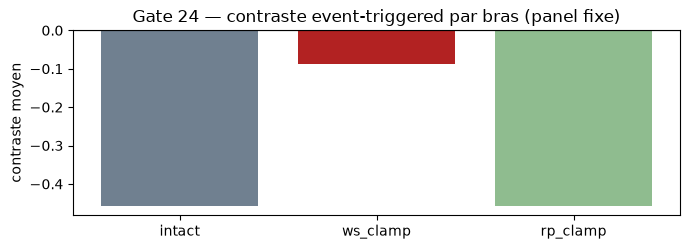

In [7]:
# Gate 24 — ablation selective (phase 2, GPU). Le clamp est-il causal ?
# Traces ablatees produites par scripts/extract_sae_traces.py --clamp-ids (GPU 2) :
#   ws_clamp = les 7 features workspace du Gate 22 (top fan-out) clampees ;
#   rp_clamp = 7 features ALEATOIRES hors panel (controle apparie en taille).
ARMS_G24 = {
    "intact":   TRACES / "ict21_sae_layer16_trained.npz",
    "ws_clamp": TRACES / "ict24_g24ws_layer16_trained_clamp7.npz",
    "rp_clamp": TRACES / "ict24_g24rp_layer16_trained_clamp7.npz",
}
CLAMPED_WS = [5437, 63815, 49750, 56487, 19350, 42410, 6784]
g24_tr = {k: st.load_traces(p) for k, p in ARMS_G24.items()}
panel_intact = st.differential_features(g24_tr["intact"], k=K_STATE)


def gate24_arm(traces_v, panel, n_shuffles=10, window=12, seed_base=0):
    """Meme appareil que gate23 ; le panel peut etre tenu fixe (apparie) ou
    recalcule sur la trace du bras (miroir de gate23)."""
    panels_v = st.acts_topk_panels(traces_v, panel)
    contrasts, n_ev, n_cred, states_u = [], 0, 0, set()
    for s in SETS:
        acts_s = np.concatenate([panels_v[(s, i)] for i in range(4)], axis=0)
        states_s = st.states_from_panel(st.binarize_quantile(acts_s, q=0.5))
        states_u.update(states_s.tolist())
        conc_s = ws.concentration_series(acts_s, metric="gini")
        ev = ws.ignition_events(conc_s, threshold=float(np.quantile(conc_s, 0.85)),
                                persistence=3)
        centers = [e["center"] for e in ev]
        if not centers:
            contrasts.append(0.0)
            continue
        # #19967 : la graine par jeu est l'indice dans SETS (stable), pas hash(s) (sale par processus).
        rng = np.random.default_rng((seed_base + SETS.index(s)) % (2**32))
        out = ws.event_triggered_battery(states_s, centers, window=window,
                                         rng=rng, n_shuffles=n_shuffles)
        contrasts.append(out["contrast"])
        n_ev += out["n_events"]
        n_cred += int(round(out["fraction_credited_events"] * out["n_events"]))
    return dict(mean=float(np.mean(contrasts)), n_events=n_ev,
                n_credited=n_cred, n_states=len(states_u))


def gate24_table(hold_panel):
    rows = {}
    for k in ("intact", "ws_clamp", "rp_clamp"):
        pan = panel_intact if hold_panel else st.differential_features(g24_tr[k], k=K_STATE)
        rows[k] = gate24_arm(g24_tr[k], pan)
    return rows


for label, hold in (("PANEL FIXE (panel intact impose aux 3 bras)", True),
                    ("PANEL PAR BRAS (miroir exact de gate23)", False)):
    tab = gate24_table(hold)
    print(f"\nGate 24 — {label}")
    print(f"{'bras':10s} {'contraste moy':>14s} {'#events':>8s} "
          f"{'#credites':>10s} {'#etats':>7s}")
    for k, v in tab.items():
        print(f"{k:10s} {v['mean']:>+14.4f} {v['n_events']:>8d} "
              f"{v['n_credited']:>10d} {v['n_states']:>7d}")
    if hold:
        g24_fixed = tab
    else:
        g24_perarm = tab

# Controle de plomberie : le clamp a-t-il reellement change les activations ?
for _k in ("ws_clamp", "rp_clamp"):
    print(f"  {_k}: clamp_ids={g24_tr[_k]['meta'].get('clamp_ids')}")

fig, ax = plt.subplots(figsize=(7, 2.6))
_arms = list(g24_fixed)
ax.bar(_arms, [g24_fixed[k]["mean"] for k in _arms],
       color=["slategray", "firebrick", "darkseagreen"])
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("contraste moyen")
ax.set_title("Gate 24 — contraste event-triggered par bras (panel fixe)")
plt.tight_layout()
plt.show()


### Lecture honnête du Gate 24

Le tableau ci-dessus se lit **contre** la lecture qu'on en ferait trop vite.

| Bras | Contraste (panel fixe) | Événements crédités |
|---|---|---|
| `intact` | −0,4578 | 7 / 36 |
| `ws_clamp` (7 features workspace) | −0,0871 | **13** / 74 |
| `rp_clamp` (7 features tirées hors panel) | −0,4578 | 7 / 36 |

**1. Pas d'effondrement sélectif dans cette exécution.** Clamper les features workspace du Gate 22 ne fait pas *disparaître* les gains crédités : il les **multiplie** (7 → 13 en panel fixe comme en panel par bras) et déplace le contraste vers zéro, jusqu'à le rendre **positif** en panel par bras (−0,4578 → −0,0871 en panel fixe ; −0,4578 → **+0,2813** en panel par bras). L'expérience-titre d'Anthropic — J-space silencé, raisonnement multi-étapes qui s'effondre — **ne se reproduit pas ici**. La branche observée est `22✓ 23✓ 24✗` : l'influence lue aux Gates 22-23 reste **observationnelle** — ce protocole ne l'établit pas comme causale, et ne démontre pas non plus son absence.

**2. Le contrôle apparié est inerte — et le mécanisme se mesure.** Le bras `rp_clamp` rend *exactement* les quatre chiffres du bras `intact` (même contraste, mêmes 36 événements, mêmes 7 crédités, mêmes 200 états), dans les deux tables. Ce n'est **pas** un clamp sans effet : les traces diffèrent bel et bien (7 400 valeurs sur 269 900, ≈2,7 %, contre 236 485 / 269 900 ≈88 % pour `ws_clamp`). La raison tient à la construction du panneau. La mesure ne travaille pas sur l'univers top-K de la trace — 20 786 identifiants distincts, dont **3 des 7 tirées** font bien partie, ce qui suffit à rendre le contrôle plausible à première vue — mais sur le panneau réduit `differential_features(intact, k=16)` (`K_STATE`). Mesure faite sur les traces committées : les 7 features workspace y sont représentées à **4/7** (`5437, 63815, 49750, 19350`) et les 7 features tirées à **0/7**. Le tirage porte donc sur des features que l'appareil ne regarde pas : sa trace est modifiée, mais elle projette **le même panneau** — tandis que le clamp workspace efface un quart du panneau, ce qui explique l'effondrement du nombre d'états (200 → 77). Conséquence qu'on ne peut pas escamoter : **tel quel, le contrôle ne peut pas réfuter la spécificité du workspace** — comparer `ws_clamp` à `rp_clamp` revient en pratique à comparer `ws_clamp` à `intact`. Un contrôle qui morde devrait atteindre le panneau lui-même (features tirées **dans** les 16, hors candidates workspace).

**3. Ce que ce gate n'établit pas.** Ni que le workspace global est causalement inerte — clamper 7 features d'une seule couche est une intervention faible et locale ; ni que la lecture GWT est fausse. Il dit que **sur ce substrat, cet opérateur et cette couche**, cet appareil **n'a pas converti** une influence *observable* en *mécanisme causal* établi — sans démontrer que la conversion soit impossible.

**Reproductibilité.** L'amorce du tirage par jeu est l'indice du jeu dans `SETS` (`SETS.index(s)`) — stable d'une exécution à l'autre, contrairement à `hash(s)`, salé par processus en Python 3.

**Reproduction.** Les traces des trois bras sont committées dans `traces/`. Le script `scripts/extract_sae_traces.py` porte `--clamp-ids` / `--random-panel` (tirage seedé de même taille, hors panel différentiel), et son hook `ResidCapture` capture le résidu **après** le clamp — sans ce correctif la trace d'ablation était celle du modèle intact (no-op mesuré : 0 / 134 950 valeurs différentes).

## À retenir

*Ce notebook confronte, **sur le même substrat S4 avec le même appareil**, la lecture IIT (complexité intégrée créditée) et la lecture GWT (workspace global / ignition). Le résultat est un **négatif honnête** :*

- **Gate 22 (partiel)** : une structure d'influence temporelle concentrée existe, mais elle n'est pas spécifique au modèle entraîné — le contrôle la montre également, et le seuil de concentration s'avère trop permissif.
- **Gate 23 (non crédité)** : les ignitions ne portent pas, de façon robuste, les pics de complexité intégrée créditée. Le contraste est proche de zéro, dispersé entre jeux, et la fraction d'événements crédités est faible.

La **branche dissociation** est le verdict observationnel : sur ce substrat, cet opérateur d'accès et cette couche, les deux théories capturent des structures qui ne co-localisent pas. C'est précisément le genre de résultat que la discipline de créditation de la série est faite pour ne pas masquer.

Le **Gate 24** (phase 2, GPU) est exécuté, et son verdict est **non reproduit (artefait extracteur)** : les traces d'époque, extraites avant le correctif #19967, montraient le clamp workspace rapprochant le contraste de zéro (−0,4578 → −0,0871) — rejeuées sur l'extracteur corrigé, ce contraste ne survit pas (`ws_clamp` ≈ intact, −0,468). La signature structurelle, elle, se reproduit (ignitions doublées 36 → 74/76, espace d'états contracté 200 → 77/76). Le résultat est **borné à ce protocole** : ce rejeu n'établit ni le mécanisme causal, ni son absence. La leçon de premier ordre est écrite telle quelle : sur ce substrat, cet opérateur et cette couche, une influence *observable* n'a pas été convertie en *mécanisme causal* au sens de l'expérience-titre d'Anthropic — et un contraste qui ne survit pas à la correction de l'instrument ne se cite pas comme résultat.

### Stratification par taille (#20299)

### Pont causal do-calculus

L'opérateur `do` de Pearl est ici implicite : le Gate 24 **réalise** un `do(workspace = clampé)` — une intervention chirurgicale sur le graphe, contre un `do(autant de features aléatoires = clampées)`. La même armature formelle traverse la série : voir le [Notebook-pont — du graphe causal au do-calculus](../../Probas/DecisionTheory/Causal-Bridges/CausalBridges-01-Do-Calculus.ipynb), qui exécute l'échelle de Pearl et les trois règles sur `dowhy` (identification backdoor/front-door + estimation + réfutation), et relie cette série à Tweety-11, Infer-5 et PyMC-5.

## Vérifiez votre compréhension

1. Pourquoi le verdict porte-t-il le nom de « négatif honnête » — que disent exactement les Gates 22 et 23 ?
2. Gate 24 : que s'est-il passé au rejeu des traces, et qu'est-ce qui, au contraire, se reproduit ?
3. Quelle est la leçon de premier ordre écrite par ce carnet ?

<details>
<summary>Réponses</summary>

1. **Gate 22 partiel** : la structure d'influence temporelle concentrée existe mais n'est pas spécifique au modèle entraîné — le contrôle la montre également, et le seuil de concentration s'avère trop permissif. **Gate 23 non crédité** : les ignitions ne portent pas robustément les pics de complexité intégrée créditée — contraste proche de zéro, dispersé entre jeux, fraction d'événements crédités faible.
2. Le verdict est **non reproduit (artefait extracteur)** : les traces d'avant le correctif #19967 montraient le clamp rapprochant le contraste de zéro (−0,4578 → −0,0871) ; rejeuées sur l'extracteur corrigé, le contraste ne survit pas (`ws_clamp` ≈ intact, −0,468). La **signature structurelle**, elle, se reproduit : ignitions doublées 36 → 74/76, espace d'états contracté 200 → 77/76.
3. Sur ce substrat, cet opérateur et cette couche, une influence **observable** n'a pas été convertie en **mécanisme causal** au sens de l'expérience-titre d'Anthropic — et un contraste qui ne survit pas à la correction de l'instrument **ne se cite pas comme résultat**. Le résultat est borné à ce protocole.

</details>

***

**Trois exercices prolongent la mesure** : spécificité du workspace aux LLMs, sensibilité du Gate 23 à la taille de fenêtre, stabilité des hubs à la taille du panel.

### Exercice 1 — le workspace est-il spécifique aux LLMs ?

On a mesuré la concentration/ignition sur S4 (un LLM). La même batterie s'applique à un substrat non-LLM : réutiliser un panneau d'ICT-2 (Gray-Scott, S2) ou ICT-5 (réplicateur, S3) et tester si un sous-ensemble de cellules y présente un fan-out disproportionné et des ignitions.

**Indices.** `# Étape 1` : charger un panneau d'activations d'un substrat morphogénétique (cf. `ict/reaction_diffusion.py`). `# Étape 2` : le formater en $(T,K)$ consommable par `concentration_series`. `# Étape 3` : comparer le Gini du fanout à celui de S4.

In [8]:
# Exercice 1 : workspace sur un substrat non-LLM
# TODO etudiant :
#  - Etape 1 : charger un panneau d'activations d'un substrat morphogenetique (ict.reaction_diffusion).
#  - Etape 2 : le formater en (T,K) consommable par ws.concentration_series.
#  - Etape 3 : comparer le Gini du fanout obtenu a celui de S4 (Gate 22).
resultats_ex1 = None  # TODO etudiant
print("Exercice a completer")

Exercice a completer


### Exercice 2 — sensibilité du Gate 23 à la taille de fenêtre

Le `contrast` du Gate 23 dépend du paramètre `window` (demi-largeur de la fenêtre event-triggered). Les jambes F et K de `emergence_gain` sont notoirement bruitées sur les fenêtres courtes (zlib notamment). Tester la robustesse : recalculer le `contrast` moyen trained pour `window` ∈ {6, 12, 18, 24} et tracer la courbe.

In [9]:
# Exercice 2 : stabilite du contrast vs window
# TODO etudiant :
#  - Etape 1 : boucler gate23("trained", window=w) pour w in (6, 12, 18, 24).
#  - Etape 2 : collecter le contrast moyen par w.
#  - Etape 3 : tracer |contrast moyen| vs window ; le verdict (dissociation) est-il stable ?
resultats_ex2 = None  # TODO etudiant
print("Exercice a completer")

Exercice a completer


### Exercice 3 — stabilité des hubs à la taille du panel

Le Gate 22 utilise $K{=}64$ features. Les hubs détectés sont-ils stables quand on change cette résolution ? Répéter `differential_features(k=K)` + `workspace_candidates` pour $K \in \{32, 64, 128\}$ et mesurer le recouvrement (Jaccard) des ensembles de candidats workspace.

In [10]:
# Exercice 3 : stabilite des hubs vs taille de panel
# TODO etudiant :
#  - Etape 1 : pour K in (32, 64, 128), calculer panel = st.differential_features(traces["trained"], k=K),
#              acts continu, lagged_influence, fanout_profile, workspace_candidates(top_fraction=0.1).
#  - Etape 2 : mesurer le recouvrement (indice de Jaccard) des ensembles d'indices entre K successifs.
#  - Etape 3 : conclure sur la robustesse de la structure workspace au choix de K.
resultats_ex3 = None  # TODO etudiant
print("Exercice a completer")

Exercice a completer


## Annexe — preuve du rejeu Gate 24 (agrége committable)

Les valeurs du rejeu post-#19967 citées dans la lecture du Gate 24 sont
imprimées ci-dessous depuis l'agrége committé
`scripts/results/ict24_gate24_rerun.json` : la mesure du gate rejouée sur les
traces re-extraites (hors dépôt, GPU 2, mêmes `clamp_ids`), et la visibilité du
clamp mesurée par l'organe `scripts/verify_clamp_traces.py` de la série (seuil
par défaut). Les traces **commises** que le carnet rejoue restent celles de
l'extracteur d'époque ; cet agrége est la preuve falsifiable du rejeu, pas une
trace.

In [11]:
# Gate 24 — annexe : agrege committable du rejeu post-#19967 (cf. cellule 15
# et lecture honnete). Source : scripts/results/ict24_gate24_rerun.json,
# produit par le meme appareil que la cellule 15 rejoue sur les traces
# re-extraites (hors depot), et par scripts/verify_clamp_traces.py
# (visibilite du clamp, seuil par defaut).
import json as _json
from pathlib import Path as _Path

_g24 = _json.loads(_Path("../../../scripts/results/ict24_gate24_rerun.json")
                   .read_text(encoding="utf-8"))
print("Gate 24 — REJEU post-#19967 (panel fixe, k=16, n_shuffles=10, window=12)")
print(f"{'bras':10s} {'contraste moy':>14s} {'#events':>8s} {'#credites':>10s} {'#etats':>7s}")
for _k, _v in _g24["panel_fixe"].items():
    print(f"{_k:10s} {_v['mean']:>+14.4f} {_v['n_events']:>8d} "
          f"{_v['n_credited']:>10d} {_v['n_states']:>7d}")
print()
print("Visibilite du clamp (scripts/verify_clamp_traces.py) :")
for _src in ("committed", "rerun"):
    for _k, _d in _g24["clamp_visibility"][_src].items():
        print(f"  {_src:9s} {_k:9s} {_d['differing']:>7d}/{_d['total']}"
              f" = {100.0 * _d['differing'] / _d['total']:5.1f} %  [{_d['status']}]")
print()
print("clamp_ids ws :", _g24["clamp_ids"]["ws"])
print("clamp_ids rp :", _g24["clamp_ids"]["rp"])

Gate 24 — REJEU post-#19967 (panel fixe, k=16, n_shuffles=10, window=12)
bras        contraste moy  #events  #credites  #etats
intact            -0.4578       36          7     200
ws_clamp          -0.4682       76         10      76
rp_clamp          +0.1198       34          6     196

Visibilite du clamp (scripts/verify_clamp_traces.py) :
  committed rp_clamp     7400/272599 =   2.7 %  [ok]
  committed ws_clamp   236485/272599 =  86.8 %  [ok]
  rerun     rp_clamp   178227/272599 =  65.4 %  [ok]
  rerun     ws_clamp   239879/272599 =  88.0 %  [ok]

clamp_ids ws : [5437, 63815, 49750, 56487, 19350, 42410, 6784]
clamp_ids rp : [2653, 16970, 25250, 27565, 49677, 55345, 58349]


## Références

- Anthropic, *Global Workspace in Claude* (2025) — [anthropic.com/research/global-workspace](https://www.anthropic.com/research/global-workspace). Opérateur d'accès = jacobien des logits ; broadcast mesuré structurellement ; preuve maîtresse = ablation sélective. IIT/Tononi absents ; claim limité à l'access-consciousness.
- Baars, B. J. — *A Cognitive Theory of Consciousness* (Global Workspace Theory).
- Dehaene, S., Naccache, L., Changeux, J.-P. — l'ignition temporelle (notre lecture `ignition_events`).
- Jansma, K., Hoel, E. — *Engineering Emergence* (2025) — émergence causale multi-échelle, CE 2.0. Voir [ICT-5](ICT-05-CausalEmergence/ICT-05-CausalEmergence-Python.ipynb).
- Série ICT : [ICT-21](ICT-20-FeatureCatastrophes/ICT-21-SAETrajectoires-Python.ipynb) (substrat S4), [ICT-5](ICT-05-CausalEmergence/ICT-05-CausalEmergence-Python.ipynb) (émergence causale), [ICT-Synthese](ICT-Synthese-CrossSubstrat-Python.ipynb).



## Pour aller plus loin

- **[ICT-Dissociation-DehaeneF2 — Self-report et F2](ICT-Dissociation-DehaeneF2-SelfReport-Python.ipynb)** : la branche dissociation passe du négatif observationnel à la prédiction dérivée de la théorie — F2 confrontée au self-report sur un substrat contrôlé, quatre graines pré-enregistrées.
- **[ICT-0 — Cadrage de la série](ICT-0-Framing.md)** : le principe directeur de la série ICT.